# 76. Calibration-fault detection from `002.27` one-step predictions

**Research question:** Can the frozen 6D-rotation-head checkpoint `002.27` identify which KAIST sensor has an incorrect calibration prior, even when it cannot accurately *correct* that prior?

We score **each sensor head independently**, with no optimization or rollouts:

\[
s^R_i = d_{SO(3)}(\Delta\hat R_i,I)\ \text{(degrees)},\quad
s^\tau_i=1000|\Delta\hat\tau_i|\ \text{(ms)},\quad
\hat y_i(r,t)=[s^R_i>r]\lor[s^\tau_i>t].
\]

The decision thresholds are **rotation** = 1, 2, 3, 4, 5° and **time** = 10, 30, 50, 75, 100 ms. All 25 OR combinations are evaluated *after* inference, without additional forward passes. We also evaluate rotation-only and time-only scores.

**Cases:** one, two, or three perturbed sensors per physical window, plus a zero-fault negative control. For each fault count, simulate `rotation_only`, `time_only`, and `both`; distribute faults among `imu`, `lidar`, and `lidar_right`. Each physical window supplies several cases. Distinct physical windows are spread over the selected held-out KAIST sequences.

**Three labeling conventions (important):**

- **`injected`:** a sensor is positive if **any nonzero perturbation was injected** into its prior, regardless of its magnitude. This matches the requested one/two/three-fault scenarios exactly.
- **`operational`:** positive if actual injected SO(3) error > `GT_ROT_TOL_DEG` **or** actual offset error > `GT_TAU_TOL_MS`. Fixed labels allow meaningful comparison of F1 across decision thresholds. The tolerance is configured independently of the decision thresholds.
- **`matched`:** actual error exceeds the **same pair of rotation/time thresholds** being tested. This answers whether the model can recognize tolerance violations at each threshold, but **F1 values across rows do not describe the same underlying classification problem**.

Healthy sensors' priors remain unchanged. Synthetic physical re-expression follows notebook 75; only the model prior is perturbed afterward. No measurement noise or sensor-topology substitution. The experiment is exclusively one-step inference.

## 1. Imports and repository APIs

In [1]:
from pathlib import Path
from dataclasses import replace
import itertools
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run this notebook inside nn-obs-calib or one of its subdirectories.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.calibration.state import CalibrationState
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import SensorStreamBatch, WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint

print('Repository:', ROOT, '| PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch: 2.7.1+cu126 | CUDA: True


## 2. Experiment settings, holdout split, thresholds and workload

In [2]:
CHECKPOINT_PATH = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt'
EVAL_SPLIT = 'validation'  # Set 'test' for a final, untouched evaluation after selecting thresholds on validation.
EVAL_SEQUENCES = {'validation': ('Urban26', 'Urban28'), 'test': ('Urban38', 'Urban39')}[EVAL_SPLIT]
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
OUTPUT_DIR = ROOT / 'runs' / '76_00227_calibration_fault_detection' / EVAL_SPLIT

CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32
RANDOM_SEED = 760_027

# Statistical coverage: up to 500 distinct physical windows across two validation sequences.
# Ten input cases per physical window = 1 clean + (3 fault counts x 3 fault modes).
WINDOWS_PER_SEQUENCE = 250
PHYSICAL_BATCH_SIZE = 4          # Raw data loading and physical augmentation batch.
INFERENCE_BATCH_SIZE = 8         # Max GPU inference microbatch, independent of the physical batch size.
AUTO_REDUCE_BATCH_ON_OOM = True   # Split a failed GPU microbatch into smaller pieces, never drop cases.
FAULT_COUNTS = (1, 2, 3)       # Their order is the reporting/evaluation order.
FAULT_MODES = ('rotation_only', 'time_only', 'both')
INCLUDE_NO_FAULT_CONTROL = True

ROTATION_THRESHOLDS_DEG = (1., 2., 3., 4., 5.)
TIME_THRESHOLDS_MS = (10., 30., 50., 75., 100.)
GT_ROT_TOL_DEG = 3.0            # Fixed, physically meaningful 'operationally unreliable' definition.
GT_TAU_TOL_MS = 50.0

# The fault sampler intentionally includes just-below/above-threshold perturbations
# AND 90...179 degree stress cases, instead of almost everything being obviously positive.
ROTATION_BINS_DEG = ((0.2, 1.), (1., 2.), (2., 3.), (3., 4.), (4., 5.), (5., 15.), (15., 45.), (45., 90.), (90., 150.), (150., 179.))
TIME_BINS_MS = ((2., 10.), (10., 30.), (30., 50.), (50., 75.), (75., 100.), (100., 150.))

# Preserve notebook 75's physical true-calibration augmentation, with zero added measurement noise.
TRUE_CALIBRATION_ROTATION_MAX_DEG = 180.0
TRUE_CALIBRATION_TAU_MAX_S = 0.030

SAVE_PLOTS = True
SHOW_PLOTS = True
PLOT_DPI = 150

if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f'002.27 checkpoint missing: {CHECKPOINT_PATH}')
if INFERENCE_BATCH_SIZE < 1 or PHYSICAL_BATCH_SIZE < 1 or WINDOWS_PER_SEQUENCE < 1:
    raise ValueError('All batch sizes and windows per sequence must be positive')
if len(set(CALIBRATION_KEYS)) != 3 or tuple(FAULT_COUNTS) != (1, 2, 3):
    raise ValueError('This diagnostic expects the three KAIST calibration keys and K=1/2/3')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if hasattr(torch.backends, 'mha'):
    torch.backends.mha.set_fastpath_enabled(False)  # Variable-length token sequences.
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
print(f'Split: {EVAL_SPLIT} | sequences: {EVAL_SEQUENCES} | checkpoint: {CHECKPOINT_PATH}')
print(f'Device: {DEVICE} | physical windows up to {WINDOWS_PER_SEQUENCE * len(EVAL_SEQUENCES)} | cases per window: 10')
print('Outputs:', OUTPUT_DIR)

Split: validation | sequences: ('Urban26', 'Urban28') | checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
Device: cuda | physical windows up to 500 | cases per window: 10
Outputs: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/76_00227_calibration_fault_detection/validation


## 3. KAIST calibration and held-out physical windows

In [3]:
# Extrinsics and LiDAR clock offsets match notebooks 68/75.
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [0., 0., 0., 1.],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0., 0., 0., 1.],
], dtype=float)
T_I_B = np.array([[1.,0.,0.,-0.07], [0.,1.,0.,0.], [0.,0.,1.,1.7], [0.,0.,0.,1.]])
rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=0.0, tau_lidar_s=-0.025, tau_lidar_right_s=-0.035,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_specs = build_kaist_sequence_specs(sequence_names=list(EVAL_SEQUENCES), kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right LiDAR poses for {spec.name}: {spec.lidar_right_pose_csv}')
eval_dataset = KAISTCalibrationDataset(all_specs, rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
assert tuple(eval_dataset.calibration_keys) == CALIBRATION_KEYS
print(eval_dataset.summary())

# Window selection is uniform over the sequence's time span (roughly independent scene coverage),
# with a seeded random phase; no contiguous 12-window rollouts are created here.
selected_windows_by_sequence = {}
rng_select = np.random.default_rng(RANDOM_SEED + 1)
for sequence in EVAL_SEQUENCES:
    available = np.asarray(eval_dataset.window_indices_for_sequence(sequence), dtype=int)
    if len(available) == 0:
        raise ValueError(f'No held-out windows available for {sequence}')
    count = min(WINDOWS_PER_SEQUENCE, len(available))
    if count == len(available):
        chosen = available
    else:
        segment_edges = np.linspace(0, len(available), count + 1, dtype=int)
        selected_positions = [int(rng_select.integers(lo, hi)) for lo, hi in zip(segment_edges[:-1], segment_edges[1:])]
        chosen = available[selected_positions]
    selected_windows_by_sequence[sequence] = chosen
    print(f'  {sequence}: {len(chosen)} distinct selected / {len(available)} available')

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658
  Urban26: 94 distinct selected / 94 available
  Urban28: 250 distinct selected / 324 available


## 4. Physical augmentation and exact `002.27` architecture

In [4]:
physical_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0 if TRUE_CALIBRATION_TAU_MAX_S > 0 else 0.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(physical_config)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)

# Do not use the newer 004.4 dimensions: this is precisely notebook 68's 002.27 architecture.
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation='gelu'),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation='gelu', dropout=0.0),
)
model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
load_training_checkpoint(CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
model.eval().requires_grad_(False)
print(f'Loaded {type(model).__name__}: {sum(p.numel() for p in model.parameters()):,} parameters')


def seeded_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))


def distance_so3_deg(R_a, R_b):
    """Stable SO(3) geodesic distance for rotations near 0 or 180 degrees."""
    R = R_a @ R_b.transpose(-1, -2)
    skew = torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    return torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(-1) - 1.0)))


@torch.inference_mode()
def model_scores(window):
    """Return actual per-head rotation (degrees) and absolute signed delta_tau (milliseconds)."""
    streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    tokens = tokenizer(streams, calibration_keys=tuple(window.current_calibration))
    predictions = model(tokens).predictions
    if set(predictions) != set(CALIBRATION_KEYS):
        raise AssertionError(f'Unexpected model prediction heads: {tuple(predictions)}')
    eye = torch.eye(3, device=DEVICE, dtype=MODEL_DTYPE)
    result = {}
    for key in CALIBRATION_KEYS:
        pred = predictions[key]
        R = pred.delta_rotation
        tau = getattr(pred, 'delta_tau', None)
        if R.ndim != 3 or R.shape[-2:] != (3, 3):
            raise ValueError(f'{key}: 002.27 must return delta_rotation [B,3,3], got {tuple(R.shape)}')
        if not isinstance(tau, torch.Tensor):
            raise AttributeError(f'{key}: 002.27 did not return delta_tau. Refusing to silently treat missing time scores as zero.')
        tau = tau.reshape(R.shape[0], -1)
        if tau.shape[1] != 1:
            raise ValueError(f'{key}: expected one time offset per sample, got {tuple(tau.shape)}')
        if not (torch.isfinite(R).all() and torch.isfinite(tau).all()):
            raise FloatingPointError(f'{key}: non-finite model output')
        result[key] = (distance_so3_deg(R, eye.expand_as(R)), (tau[:, 0] * 1000.0))
    return result

# Run one true model inference as an early compatibility and tensor-shape check.
with torch.inference_mode():
    smoke_raw = window_batch_to(collate_windows([eval_dataset[int(selected_windows_by_sequence[EVAL_SEQUENCES[0]][0])]]), DEVICE, dtype=MODEL_DTYPE)
    smoke_physical = physical_augmenter(smoke_raw, generator=seeded_generator(RANDOM_SEED + 17)).augmented_window
    smoke_window = WindowBatch(streams=dict(smoke_physical.streams), current_calibration=dict(smoke_physical.current_calibration), metadata=dict(smoke_physical.metadata), targets=None, dataset_indices=None)
    smoke_scores = model_scores(smoke_window)
    print('002.27 one-step prediction interface:')
    for k, (rot, tau) in smoke_scores.items():
        print(f'  {k:11s} rotation={rot.detach().cpu().numpy().round(3)} deg; signed time={tau.detach().cpu().numpy().round(3)} ms')

Loaded PooledCalibration6DModel: 2,554,570 parameters
002.27 one-step prediction interface:
  imu         rotation=[0.132] deg; signed time=[-0.201] ms
  lidar       rotation=[1.655] deg; signed time=[-18.059] ms
  lidar_right rotation=[1.142] deg; signed time=[17.827] ms


## 5. Batched case sampler: 0, 1, 2 or 3 faulty sensor priors

In [5]:
def draw_magnitude(rng, bins):
    lower, upper = bins[int(rng.integers(len(bins)))]
    return float(rng.uniform(lower, upper))


def generate_cases(source_indices, sequence, original_indices, rng, next_case_id):
    """One clean control and three mode-balanced samples for each K=1,2,3, per physical window."""
    cases = []
    for row, original_index in zip(source_indices, original_indices):
        for k in FAULT_COUNTS:
            for mode in FAULT_MODES:
                selected_keys = tuple(sorted(rng.choice(CALIBRATION_KEYS, size=k, replace=False).tolist()))
                rotations = {key: 0.0 for key in CALIBRATION_KEYS}
                tau_ms = {key: 0.0 for key in CALIBRATION_KEYS}
                axes = {key: np.zeros(3, dtype=float) for key in CALIBRATION_KEYS}
                for key in selected_keys:
                    if mode in ('rotation_only', 'both'):
                        rotations[key] = draw_magnitude(rng, ROTATION_BINS_DEG)
                        u = rng.normal(size=3)
                        axes[key] = u / np.linalg.norm(u)
                    if mode in ('time_only', 'both'):
                        tau_ms[key] = draw_magnitude(rng, TIME_BINS_MS) * int(rng.choice((-1, 1)))
                cases.append(dict(case_id=next_case_id, source_row=int(row), sequence=sequence, physical_index=int(original_index),
                                  fault_count=k, fault_mode=mode, injected_keys=selected_keys,
                                  rotations=rotations, tau_ms=tau_ms, axes=axes))
                next_case_id += 1
        if INCLUDE_NO_FAULT_CONTROL:
            cases.append(dict(case_id=next_case_id, source_row=int(row), sequence=sequence, physical_index=int(original_index),
                              fault_count=0, fault_mode='none', injected_keys=(),
                              rotations={key: 0.0 for key in CALIBRATION_KEYS},
                              tau_ms={key: 0.0 for key in CALIBRATION_KEYS},
                              axes={key: np.zeros(3, dtype=float) for key in CALIBRATION_KEYS}))
            next_case_id += 1
    return cases, next_case_id


@torch.inference_mode()
def make_faulted_minibatch(physical, cases):
    """Duplicate ONLY the requested physical examples; inject all faults in a vectorized SO(3) operation."""
    source_rows = torch.tensor([entry['source_row'] for entry in cases], dtype=torch.long, device=DEVICE)
    batch_n = len(cases)
    streams = {}
    for key, stream in physical.streams.items():
        streams[key] = SensorStreamBatch(
            values=stream.values.index_select(0, source_rows),
            timestamps=stream.timestamps.index_select(0, source_rows),
            sample_mask=stream.sample_mask.index_select(0, source_rows),
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.index_select(0, source_rows),
        )
    states = {}
    for key, state in physical.current_calibration.items():
        T_truth = state.transform.index_select(0, source_rows)
        tau_truth = state.time_offset.index_select(0, source_rows)
        angles = torch.tensor([entry['rotations'][key] for entry in cases], device=DEVICE, dtype=MODEL_DTYPE)
        axes = torch.as_tensor(np.stack([entry['axes'][key] for entry in cases]), device=DEVICE, dtype=MODEL_DTYPE)
        delta_R = so3_exp(torch.deg2rad(angles)[:, None] * axes)
        T_prior = T_truth.clone()
        T_prior[:, :3, :3] = delta_R @ T_truth[:, :3, :3]
        tau_delta = torch.tensor([entry['tau_ms'][key] * 1e-3 for entry in cases], device=DEVICE, dtype=MODEL_DTYPE)
        if tau_truth.numel() != batch_n:
            raise AssertionError(f'{key}: unexpected time offset shape {tuple(tau_truth.shape)}')
        tau_prior = tau_truth + tau_delta.reshape_as(tau_truth)
        states[key] = CalibrationState(transform=T_prior, time_offset=tau_prior)
        # Verify actual injected errors, not just the intended values.
        actual_angles = distance_so3_deg(T_prior[:, :3, :3], T_truth[:, :3, :3])
        if not bool((actual_angles - angles).abs().max() < 0.2):
            raise AssertionError(f'{key}: injected angle differs from constructed prior')
        if not bool((1000.0 * (tau_prior - tau_truth).reshape(-1) - 1000.0 * tau_delta).abs().max() < 0.1):
            raise AssertionError(f'{key}: injected time offset differs from constructed prior')
    return WindowBatch(streams=streams, current_calibration=states, metadata=dict(physical.metadata), targets=None, dataset_indices=None)


@torch.inference_mode()
def evaluate_chunk(physical, cases, batch_size):
    """Adaptive microbatches. OOM handling retries exactly the SAME cases, with no resampling."""
    results = []
    position = 0
    while position < len(cases):
        subset = cases[position: position + batch_size]
        batch = None
        try:
            batch = make_faulted_minibatch(physical, subset)
            scores = model_scores(batch)
        except torch.cuda.OutOfMemoryError:
            if not (AUTO_REDUCE_BATCH_ON_OOM and DEVICE.type == 'cuda' and batch_size > 1):
                raise
            batch = None
            torch.cuda.empty_cache()
            batch_size = max(1, batch_size // 2)
            print(f'CUDA OOM: retrying unchanged cases with inference batch size {batch_size}', flush=True)
            continue
        cpu_scores = {key: (rot.detach().cpu().numpy(), tau.detach().cpu().numpy()) for key, (rot, tau) in scores.items()}
        for j, entry in enumerate(subset):
            for key in CALIBRATION_KEYS:
                rot_score, tau_score = cpu_scores[key]
                results.append(dict(case_id=entry['case_id'], sequence=entry['sequence'], physical_index=entry['physical_index'],
                                    fault_count=entry['fault_count'], fault_mode=entry['fault_mode'], sensor=key,
                                    injected_sensor=int(key in entry['injected_keys']),
                                    true_rotation_deg=entry['rotations'][key], true_tau_ms=entry['tau_ms'][key],
                                    predicted_rotation_deg=float(rot_score[j]), predicted_tau_ms=float(tau_score[j]),
                                    predicted_abs_tau_ms=abs(float(tau_score[j]))))
        position += len(subset)
        del batch, scores, cpu_scores
    return results

print('Sampler ready. Faults are injected into calibration priors; measurements are not modified after physical rendering.')

Sampler ready. Faults are injected into calibration priors; measurements are not modified after physical rendering.


## 6. Run **one** batched inference pass over all scenarios and persist scores

In [6]:
@torch.inference_mode()
def collect_scores():
    rng = np.random.default_rng(RANDOM_SEED + 123)
    rows = []
    next_case_id = 0
    total_physical_batches = sum((len(indices) + PHYSICAL_BATCH_SIZE - 1) // PHYSICAL_BATCH_SIZE for indices in selected_windows_by_sequence.values())
    physical_batch_number = 0
    start_time = time.monotonic()
    for sequence_index, sequence in enumerate(EVAL_SEQUENCES):
        chosen = selected_windows_by_sequence[sequence]
        for start in range(0, len(chosen), PHYSICAL_BATCH_SIZE):
            original_indices = chosen[start:start + PHYSICAL_BATCH_SIZE]
            raw = window_batch_to(collate_windows([eval_dataset[int(idx)] for idx in original_indices]), DEVICE, dtype=MODEL_DTYPE)
            seed = RANDOM_SEED + sequence_index * 1_000_003 + start * 1009
            physical = physical_augmenter(raw, generator=seeded_generator(seed)).augmented_window
            cases, next_case_id = generate_cases(range(len(original_indices)), sequence, original_indices, rng, next_case_id)
            rows.extend(evaluate_chunk(physical, cases, INFERENCE_BATCH_SIZE))
            physical_batch_number += 1
            if physical_batch_number % 10 == 0 or physical_batch_number == total_physical_batches:
                print(f'{physical_batch_number:4d}/{total_physical_batches} physical batches | '
                      f'{next_case_id:,} cases | {len(rows):,} head predictions | '
                      f'elapsed {time.monotonic() - start_time:.1f}s', flush=True)
            del raw, physical
    df = pd.DataFrame(rows)
    if df.empty:
        raise AssertionError('No evaluations were generated')
    if df.groupby('case_id').sensor.nunique().ne(len(CALIBRATION_KEYS)).any():
        raise AssertionError('Missing or duplicated sensor heads in one of the cases')
    if (df[['true_rotation_deg', 'true_tau_ms', 'predicted_rotation_deg', 'predicted_tau_ms']].isna().any().any()):
        raise FloatingPointError('Non-finite injected errors or predicted scores')
    df.to_csv(OUTPUT_DIR / 'one_step_sensor_scores.csv', index=False)
    print(f'Finished. Unique physical windows: {df[["sequence", "physical_index"]].drop_duplicates().shape[0]}, '
          f'cases: {df.case_id.nunique():,}, head scores: {len(df):,}')
    return df

# Change to False to reload cached scores and re-sweep thresholds without any model inference.
RUN_MODEL_INFERENCE = True
if RUN_MODEL_INFERENCE:
    score_df = collect_scores()
else:
    score_df = pd.read_csv(OUTPUT_DIR / 'one_step_sensor_scores.csv')

print('\nCase counts by number of faults and type:')
display(score_df[['case_id', 'fault_count', 'fault_mode']].drop_duplicates().groupby(['fault_count', 'fault_mode']).size().rename('cases').reset_index())
print('\nSensor fault counts (directly injected):')
display(score_df.groupby(['fault_count', 'sensor']).injected_sensor.agg(['size', 'sum', 'mean']).round(3))

  10/87 physical batches | 400 cases | 1,200 head predictions | elapsed 6.6s
  20/87 physical batches | 800 cases | 2,400 head predictions | elapsed 12.9s
  30/87 physical batches | 1,180 cases | 3,540 head predictions | elapsed 19.0s
  40/87 physical batches | 1,580 cases | 4,740 head predictions | elapsed 25.1s
  50/87 physical batches | 1,980 cases | 5,940 head predictions | elapsed 31.3s
  60/87 physical batches | 2,380 cases | 7,140 head predictions | elapsed 38.2s
  70/87 physical batches | 2,780 cases | 8,340 head predictions | elapsed 44.7s
  80/87 physical batches | 3,180 cases | 9,540 head predictions | elapsed 50.7s
  87/87 physical batches | 3,440 cases | 10,320 head predictions | elapsed 54.7s
Finished. Unique physical windows: 344, cases: 3,440, head scores: 10,320

Case counts by number of faults and type:


,fault_count,fault_mode,cases
0,0,none,344
1,1,both,344
2,1,rotation_only,344
3,1,time_only,344
4,2,both,344
5,2,rotation_only,344
6,2,time_only,344
7,3,both,344
8,3,rotation_only,344
9,3,time_only,344



Sensor fault counts (directly injected):


size   sum   mean
fault_count sensor                        
0           imu           344     0  0.000
            lidar         344     0  0.000
            lidar_right   344     0  0.000
1           imu          1032   353  0.342
            lidar        1032   364  0.353
            lidar_right  1032   315  0.305
2           imu          1032   678  0.657
            lidar        1032   721  0.699
            lidar_right  1032   665  0.644
3           imu          1032  1032  1.000
            lidar        1032  1032  1.000
            lidar_right  1032  1032  1.000

## 7. Compute precision / recall / F1 without repeating inference

The OR alarm triggers when **either** rotation **or** time score exceeds its decision threshold. For each pair of thresholds we compute `TP, FP, FN, TN`, precision, recall, F1, accuracy, specificity, positive prevalence and alarm rate. Results are **micro-averaged over sensor decisions**, with breakdowns by fault count, sensor and perturbation type.

`K=3` with `injected` labels has only positive sensors, so it cannot estimate false positives or specificity. The zero-fault controls and K=1/2 cases supply true negatives.

In [7]:
def metrics_from_counts(tp, fp, fn, tn):
    n = tp + fp + fn + tn
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan
    specificity = tn / (tn + fp) if tn + fp else np.nan
    return dict(n=int(n), positives=int(tp + fn), negatives=int(tn + fp), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
                precision=precision, recall=recall, f1=f1, accuracy=(tp + tn) / n if n else np.nan,
                specificity=specificity, false_positive_rate=fp / (fp + tn) if fp + tn else np.nan,
                alarm_rate=(tp + fp) / n if n else np.nan, prevalence=(tp + fn) / n if n else np.nan)


def evaluate_joint_thresholds(df, *, group_name, grouping, ground_truth_mode):
    """Score all 25 OR rules using cached outputs, no neural network forward calls."""
    rot_true = df.true_rotation_deg.to_numpy(dtype=float)
    tau_true = np.abs(df.true_tau_ms.to_numpy(dtype=float))
    rot_pred = df.predicted_rotation_deg.to_numpy(dtype=float)
    tau_pred = df.predicted_abs_tau_ms.to_numpy(dtype=float)
    injected = df.injected_sensor.to_numpy(dtype=bool)
    rows = []
    for rot_t, tau_t in itertools.product(ROTATION_THRESHOLDS_DEG, TIME_THRESHOLDS_MS):
        pred = (rot_pred > rot_t) | (tau_pred > tau_t)
        if ground_truth_mode == 'injected':
            truth = injected
        elif ground_truth_mode == 'operational':
            truth = (rot_true > GT_ROT_TOL_DEG) | (tau_true > GT_TAU_TOL_MS)
        elif ground_truth_mode == 'matched':
            truth = (rot_true > rot_t) | (tau_true > tau_t)
        else:
            raise ValueError(ground_truth_mode)
        tp = int(np.count_nonzero(pred & truth))
        fp = int(np.count_nonzero(pred & ~truth))
        fn = int(np.count_nonzero(~pred & truth))
        tn = int(np.count_nonzero(~pred & ~truth))
        rows.append(dict(group_name=group_name, group_value=str(grouping), ground_truth_mode=ground_truth_mode,
                         rot_threshold_deg=rot_t, time_threshold_ms=tau_t, **metrics_from_counts(tp, fp, fn, tn)))
    return rows


def build_joint_threshold_sweep(df):
    parts = [('fault_count', 'all', df)]
    parts.extend(('fault_count', str(k), df[df.fault_count == k]) for k in (0, 1, 2, 3))
    parts.extend(('sensor', name, df[df.sensor == name]) for name in CALIBRATION_KEYS)
    parts.extend(('fault_mode', mode, df[df.fault_mode == mode]) for mode in ('none', *FAULT_MODES))
    for k in (1, 2, 3):
        parts.extend(('fault_count_sensor', f'{k}|{sensor}', df[(df.fault_count == k) & (df.sensor == sensor)]) for sensor in CALIBRATION_KEYS)
        parts.extend(('fault_count_mode', f'{k}|{mode}', df[(df.fault_count == k) & (df.fault_mode == mode)]) for mode in FAULT_MODES)
    output = []
    for group_name, group_value, subset in parts:
        if subset.empty:
            continue
        for ground_truth_mode in ('injected', 'operational', 'matched'):
            output.extend(evaluate_joint_thresholds(subset, group_name=group_name, grouping=group_value, ground_truth_mode=ground_truth_mode))
    result = pd.DataFrame(output)
    result.to_csv(OUTPUT_DIR / 'joint_25_thresholds_metrics.csv', index=False)
    return result


joint_df = build_joint_threshold_sweep(score_df)
print('Total threshold summary rows:', len(joint_df), '| saved joint_25_thresholds_metrics.csv')
print('\nFixed operational ground-truth positives have the same meaning for every decision threshold.')

for k in (1, 2, 3, 'all'):
    subset = joint_df[(joint_df.group_name == 'fault_count') & (joint_df.group_value == str(k)) &
                      (joint_df.ground_truth_mode == 'operational')]
    print(f'\nK = {k}: precision/recall/F1 across rotation and time thresholds (fixed operational GT)')
    display(subset[['rot_threshold_deg', 'time_threshold_ms', 'n', 'positives', 'tp', 'fp', 'fn', 'tn',
                    'precision', 'recall', 'f1', 'specificity']].round(3))

print('\nExamples at rotation=3° / time=50ms: all GT conventions, K=1/2/3 and clean controls:')
display(joint_df[(joint_df.group_name == 'fault_count') & (joint_df.rot_threshold_deg == 3) &
                 (joint_df.time_threshold_ms == 50)][['group_value','ground_truth_mode','n','positives','tp','fp','fn','tn',
                                                      'precision','recall','f1','specificity']].round(3))

Total threshold summary rows: 2250 | saved joint_25_thresholds_metrics.csv

Fixed operational ground-truth positives have the same meaning for every decision threshold.

K = 1: precision/recall/F1 across rotation and time thresholds (fixed operational GT)


,rot_threshold_deg,time_threshold_ms,n,positives,tp,fp,fn,tn,precision,recall,f1,specificity
175,1.0,10.0,3096,689,668,611,21,1796,0.522,0.970,0.679,0.746
176,1.0,30.0,3096,689,663,494,26,1913,0.573,0.962,0.718,0.795
177,1.0,50.0,3096,689,658,480,31,1927,0.578,0.955,0.720,0.801
178,1.0,75.0,3096,689,648,480,41,1927,0.574,0.940,0.713,0.801
179,1.0,100.0,3096,689,640,480,49,1927,0.571,0.929,0.708,0.801
180,2.0,10.0,3096,689,652,467,37,1940,0.583,0.946,0.721,0.806
181,2.0,30.0,3096,689,637,253,52,2154,0.716,0.925,0.807,0.895
182,2.0,50.0,3096,689,626,220,63,2187,0.740,0.909,0.816,0.909
183,2.0,75.0,3096,689,597,218,92,2189,0.733,0.866,0.794,0.909
184,2.0,100.0,3096,689,566,218,123,2189,0.722,0.821,0.768,0.909



K = 2: precision/recall/F1 across rotation and time thresholds (fixed operational GT)


,rot_threshold_deg,time_threshold_ms,n,positives,tp,fp,fn,tn,precision,recall,f1,specificity
250,1.0,10.0,3096,1434,1023,314,411,1348,0.765,0.713,0.738,0.811
251,1.0,30.0,3096,1434,991,253,443,1409,0.797,0.691,0.740,0.848
252,1.0,50.0,3096,1434,974,243,460,1419,0.800,0.679,0.735,0.854
253,1.0,75.0,3096,1434,954,242,480,1420,0.798,0.665,0.725,0.854
254,1.0,100.0,3096,1434,944,241,490,1421,0.797,0.658,0.721,0.855
255,2.0,10.0,3096,1434,995,255,439,1407,0.796,0.694,0.741,0.847
256,2.0,30.0,3096,1434,951,156,483,1506,0.859,0.663,0.749,0.906
257,2.0,50.0,3096,1434,922,128,512,1534,0.878,0.643,0.742,0.923
258,2.0,75.0,3096,1434,876,126,558,1536,0.874,0.611,0.719,0.924
259,2.0,100.0,3096,1434,845,125,589,1537,0.871,0.589,0.703,0.925



K = 3: precision/recall/F1 across rotation and time thresholds (fixed operational GT)


,rot_threshold_deg,time_threshold_ms,n,positives,tp,fp,fn,tn,precision,recall,f1,specificity
325,1.0,10.0,3096,2109,1156,240,953,747,0.828,0.548,0.660,0.757
326,1.0,30.0,3096,2109,1128,199,981,788,0.850,0.535,0.657,0.798
327,1.0,50.0,3096,2109,1113,190,996,797,0.854,0.528,0.652,0.807
328,1.0,75.0,3096,2109,1100,189,1009,798,0.853,0.522,0.647,0.809
329,1.0,100.0,3096,2109,1083,189,1026,798,0.851,0.514,0.641,0.809
330,2.0,10.0,3096,2109,1112,202,997,785,0.846,0.527,0.650,0.795
331,2.0,30.0,3096,2109,1074,132,1035,855,0.891,0.509,0.648,0.866
332,2.0,50.0,3096,2109,1045,106,1064,881,0.908,0.495,0.641,0.893
333,2.0,75.0,3096,2109,1006,103,1103,884,0.907,0.477,0.625,0.896
334,2.0,100.0,3096,2109,965,102,1144,885,0.904,0.458,0.608,0.897



K = all: precision/recall/F1 across rotation and time thresholds (fixed operational GT)


,rot_threshold_deg,time_threshold_ms,n,positives,tp,fp,fn,tn,precision,recall,f1,specificity
25,1.0,10.0,10320,4232,2847,1600,1385,4488,0.640,0.673,0.656,0.737
26,1.0,30.0,10320,4232,2782,1239,1450,4849,0.692,0.657,0.674,0.796
27,1.0,50.0,10320,4232,2745,1205,1487,4883,0.695,0.649,0.671,0.802
28,1.0,75.0,10320,4232,2702,1203,1530,4885,0.692,0.638,0.664,0.802
29,1.0,100.0,10320,4232,2667,1202,1565,4886,0.689,0.630,0.658,0.803
30,2.0,10.0,10320,4232,2759,1255,1473,4833,0.687,0.652,0.669,0.794
31,2.0,30.0,10320,4232,2662,659,1570,5429,0.802,0.629,0.705,0.892
32,2.0,50.0,10320,4232,2593,569,1639,5519,0.820,0.613,0.701,0.907
33,2.0,75.0,10320,4232,2479,561,1753,5527,0.815,0.586,0.682,0.908
34,2.0,100.0,10320,4232,2376,559,1856,5529,0.810,0.561,0.663,0.908



Examples at rotation=3° / time=50ms: all GT conventions, K=1/2/3 and clean controls:


,group_value,ground_truth_mode,n,positives,tp,fp,fn,tn,precision,recall,f1,specificity
12,all,injected,10320,6192,2692,172,3500,3956,0.940,0.435,0.595,0.958
37,all,operational,10320,4232,2508,356,1724,5732,0.876,0.593,0.707,0.942
62,all,matched,10320,4232,2508,356,1724,5732,0.876,0.593,0.707,0.942
87,0,injected,1032,0,0,73,0,959,0.000,NaN,0.000,0.929
112,0,operational,1032,0,0,73,0,959,0.000,NaN,0.000,0.929
137,0,matched,1032,0,0,73,0,959,0.000,NaN,0.000,0.929
162,1,injected,3096,1032,656,81,376,1983,0.890,0.636,0.742,0.961
187,1,operational,3096,689,602,135,87,2272,0.817,0.874,0.844,0.944
212,1,matched,3096,689,602,135,87,2272,0.817,0.874,0.844,0.944
237,2,injected,3096,2064,960,18,1104,1014,0.982,0.465,0.631,0.983


## 8. Separate rotation-only and time-only classifier sweeps

In [8]:
def build_single_modality_sweep(df):
    rows = []
    groupings = [('all', df)] + [(str(k), df[df.fault_count == k]) for k in (0, 1, 2, 3)]
    for group, subset in groupings:
        if subset.empty:
            continue
        for modality, thresholds, actual_column, pred_column in (
            ('rotation', ROTATION_THRESHOLDS_DEG, 'true_rotation_deg', 'predicted_rotation_deg'),
            ('time', TIME_THRESHOLDS_MS, 'true_tau_ms', 'predicted_abs_tau_ms'),
        ):
            actual = np.abs(subset[actual_column].to_numpy(dtype=float))
            predicted = np.abs(subset[pred_column].to_numpy(dtype=float))
            for threshold in thresholds:
                truth = actual > threshold
                alarm = predicted > threshold
                tp = int(np.count_nonzero(alarm & truth))
                fp = int(np.count_nonzero(alarm & ~truth))
                fn = int(np.count_nonzero(~alarm & truth))
                tn = int(np.count_nonzero(~alarm & ~truth))
                rows.append(dict(fault_count=group, modality=modality, threshold=float(threshold),
                                 threshold_units='deg' if modality == 'rotation' else 'ms',
                                 **metrics_from_counts(tp, fp, fn, tn)))
    return pd.DataFrame(rows)

modality_df = build_single_modality_sweep(score_df)
modality_df.to_csv(OUTPUT_DIR / 'rotation_and_time_separate_metrics.csv', index=False)
print('Individually thresholded rotation and time corrections (actual error threshold-matched):')
display(modality_df[['fault_count','modality','threshold','positives','tp','fp','fn','tn','precision','recall','f1']].round(3))

Individually thresholded rotation and time corrections (actual error threshold-matched):


,fault_count,modality,threshold,positives,tp,fp,fn,tn,precision,recall,f1
0,all,rotation,1.0,3737,2232,1602,1505,4981,0.582,0.597,0.590
1,all,rotation,2.0,3329,1952,852,1377,6139,0.696,0.586,0.637
2,all,rotation,3.0,2908,1761,600,1147,6812,0.746,0.606,0.668
3,all,rotation,4.0,2489,1637,441,852,7390,0.788,0.658,0.717
4,all,rotation,5.0,2095,1537,328,558,7897,0.824,0.734,0.776
5,all,time,10.0,3450,2026,1202,1424,5668,0.628,0.587,0.607
6,all,time,30.0,2746,1529,223,1217,7351,0.873,0.557,0.680
7,all,time,50.0,2041,1120,110,921,8169,0.911,0.549,0.685
8,all,time,75.0,1361,708,83,653,8876,0.895,0.520,0.658
9,all,time,100.0,664,342,91,322,9565,0.790,0.515,0.624


## 9. Figures: K=1/2/3 threshold heatmaps, precision/recall/F1 and actual score distributions

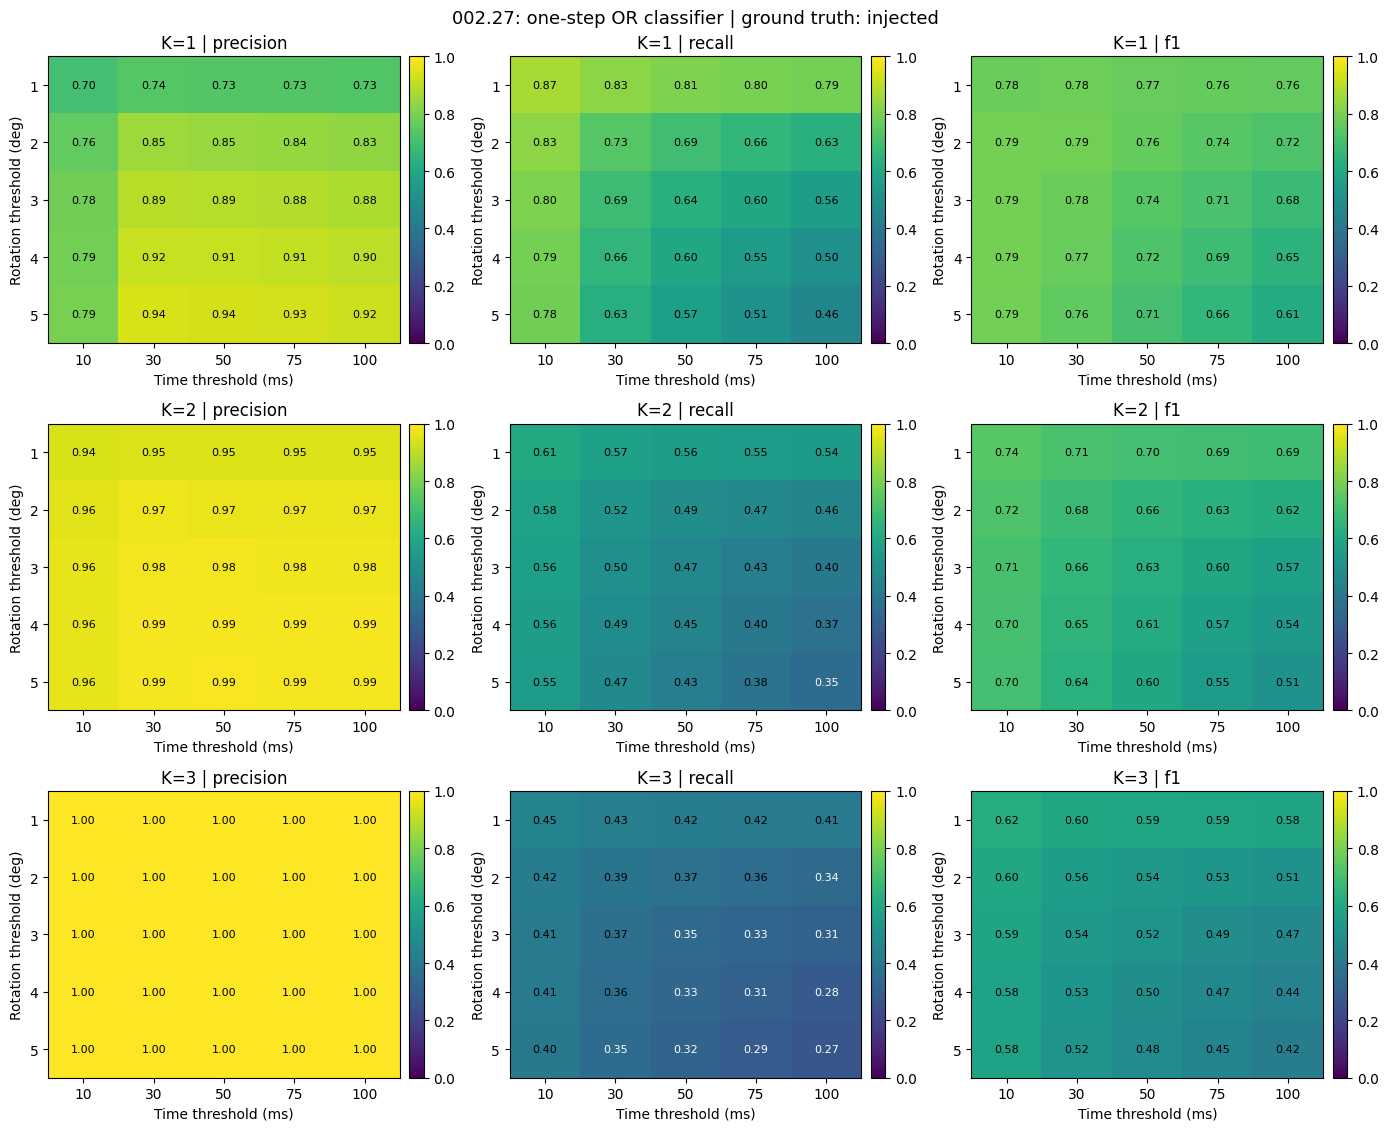

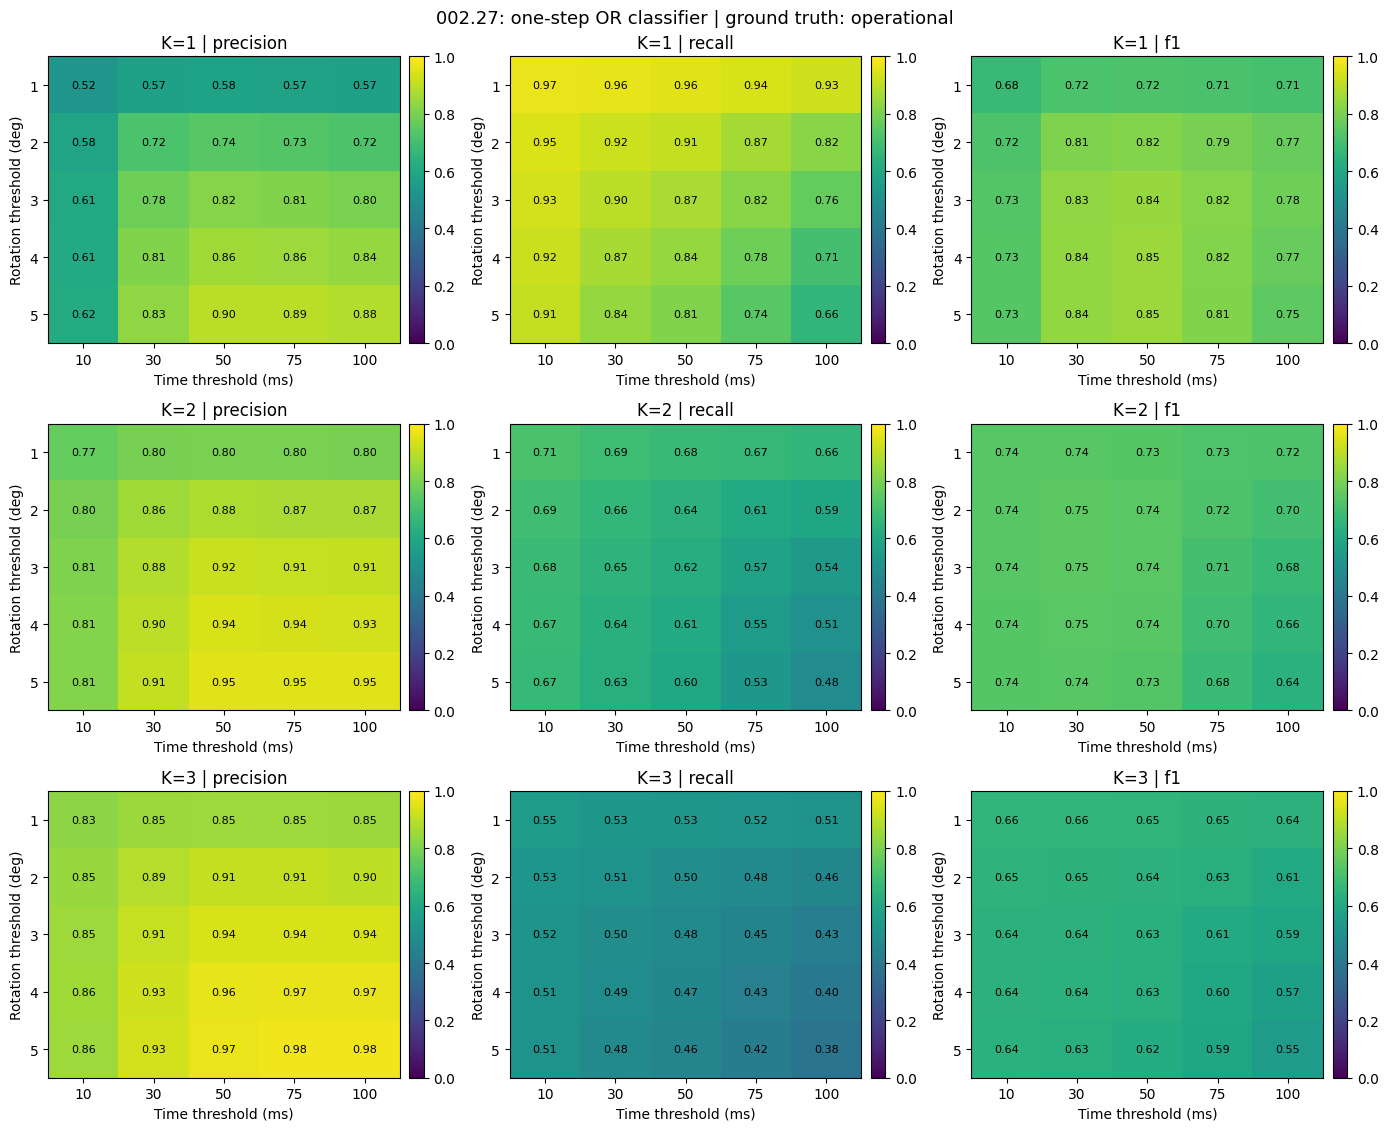

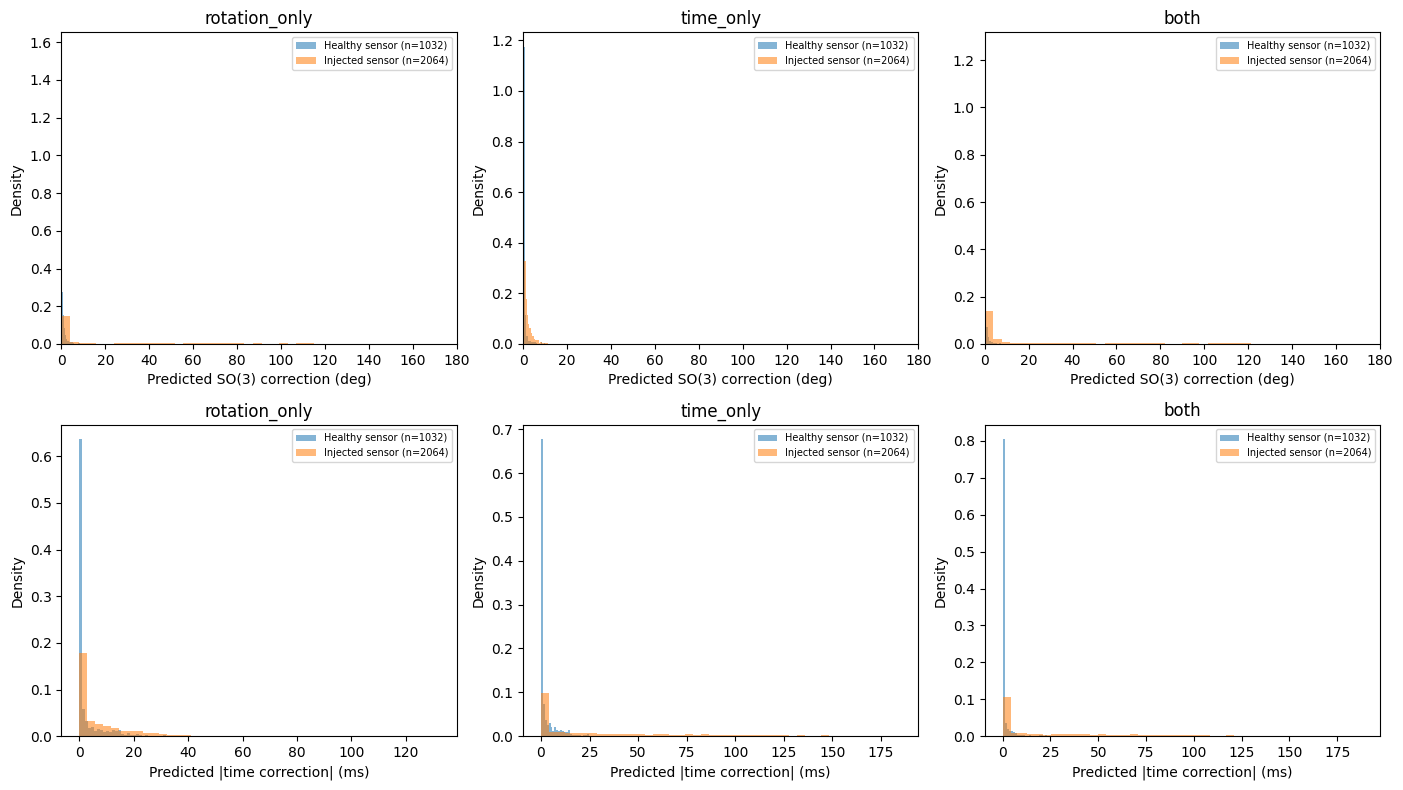

,rot_threshold_deg,time_threshold_ms,n,fp,tn,false_positive_rate
75,1.0,10.0,1032,435,597,0.422
76,1.0,30.0,1032,293,739,0.284
77,1.0,50.0,1032,292,740,0.283
78,1.0,75.0,1032,292,740,0.283
79,1.0,100.0,1032,292,740,0.283
80,2.0,10.0,1032,331,701,0.321
81,2.0,30.0,1032,118,914,0.114
82,2.0,50.0,1032,115,917,0.111
83,2.0,75.0,1032,114,918,0.110
84,2.0,100.0,1032,114,918,0.110


In [9]:
def finish_figure(fig, filename):
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(OUTPUT_DIR / filename, dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


for gt_mode in ('injected', 'operational'):
    fig, axes = plt.subplots(3, 3, figsize=(14.0, 11.5), squeeze=False)
    for row, k in enumerate((1, 2, 3)):
        subset = joint_df[(joint_df.group_name == 'fault_count') & (joint_df.group_value == str(k)) &
                          (joint_df.ground_truth_mode == gt_mode)]
        for column, metric in enumerate(('precision', 'recall', 'f1')):
            values = subset.pivot(index='rot_threshold_deg', columns='time_threshold_ms', values=metric).reindex(
                index=ROTATION_THRESHOLDS_DEG, columns=TIME_THRESHOLDS_MS)
            im = axes[row, column].imshow(values.to_numpy(float), cmap='viridis', vmin=0, vmax=1, aspect='auto')
            axes[row, column].set_xticks(range(len(TIME_THRESHOLDS_MS)), [str(int(t)) for t in TIME_THRESHOLDS_MS])
            axes[row, column].set_yticks(range(len(ROTATION_THRESHOLDS_DEG)), [str(int(t)) for t in ROTATION_THRESHOLDS_DEG])
            axes[row, column].set_xlabel('Time threshold (ms)')
            axes[row, column].set_ylabel('Rotation threshold (deg)')
            axes[row, column].set_title(f'K={k} | {metric}')
            for (i, j), value in np.ndenumerate(values.to_numpy(float)):
                if np.isfinite(value):
                    axes[row, column].text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
                                           color='white' if value < 0.35 else 'black')
            fig.colorbar(im, ax=axes[row, column], fraction=0.045, pad=0.025)
    fig.suptitle(f'002.27: one-step OR classifier | ground truth: {gt_mode}', fontsize=13)
    finish_figure(fig, f'joint_threshold_grid_{gt_mode}.png')

# Look at absolute output magnitudes separately for healthy / perturbed heads and type of injected fault.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for column, mode in enumerate(FAULT_MODES):
    subset = score_df[score_df.fault_mode == mode]
    for row, (field, xlabel, limit) in enumerate((
        ('predicted_rotation_deg', 'Predicted SO(3) correction (deg)', 180),
        ('predicted_abs_tau_ms', 'Predicted |time correction| (ms)', None),
    )):
        for is_fault, label in ((0, 'Healthy sensor'), (1, 'Injected sensor')):
            data = subset[subset.injected_sensor == is_fault][field].to_numpy(float)
            if len(data):
                axes[row, column].hist(data, bins=45, alpha=0.55, density=True, label=f'{label} (n={len(data)})')
        axes[row, column].set_title(mode)
        axes[row, column].set_xlabel(xlabel)
        axes[row, column].set_ylabel('Density')
        if limit is not None:
            axes[row, column].set_xlim(0, limit)
        axes[row, column].legend(fontsize=7)
finish_figure(fig, 'predicted_score_distributions_by_fault_type.png')

# False-positive rates on genuinely untouched priors, independent of the active K scenario.
clean_df = joint_df[(joint_df.group_name == 'fault_count') & (joint_df.group_value == '0') &
                    (joint_df.ground_truth_mode == 'injected')]
if len(clean_df):
    display(clean_df[['rot_threshold_deg', 'time_threshold_ms', 'n', 'fp', 'tn', 'false_positive_rate']].round(3))

## 10. Inspect false positives, missed faults and per-sensor differences

In [10]:
# Select a representative operating point for case-level inspection.
INSPECT_ROT_THRESHOLD_DEG = 3.0
INSPECT_TIME_THRESHOLD_MS = 50.0

inspect_df = score_df.copy()
inspect_df['alarm_rot'] = inspect_df.predicted_rotation_deg > INSPECT_ROT_THRESHOLD_DEG
inspect_df['alarm_time'] = inspect_df.predicted_abs_tau_ms > INSPECT_TIME_THRESHOLD_MS
inspect_df['alarm'] = inspect_df.alarm_rot | inspect_df.alarm_time
inspect_df['operational_truth'] = (inspect_df.true_rotation_deg > GT_ROT_TOL_DEG) | (inspect_df.true_tau_ms.abs() > GT_TAU_TOL_MS)
inspect_df['outcome'] = np.select([
    inspect_df.alarm & inspect_df.operational_truth,
    inspect_df.alarm & ~inspect_df.operational_truth,
    ~inspect_df.alarm & inspect_df.operational_truth,
], ['TP', 'FP', 'FN'], default='TN')

print(f'Operating point: rot > {INSPECT_ROT_THRESHOLD_DEG:g}°, time > {INSPECT_TIME_THRESHOLD_MS:g}ms')
print('Per-sensor, per-fault-count confusion matrix:')
confusion_df = inspect_df.pivot_table(index=['fault_count','sensor'], columns='outcome', values='case_id', aggfunc='size', fill_value=0)
for missing in ('TP', 'FP', 'FN', 'TN'):
    if missing not in confusion_df.columns:
        confusion_df[missing] = 0
confusion_df = confusion_df[['TP', 'FP', 'FN', 'TN']]
display(confusion_df)
confusion_df.to_csv(OUTPUT_DIR / 'selected_threshold_confusion_by_sensor.csv')

print('\nExamples of *false positives* (healthy or below operational tolerances, but alarmed):')
display(inspect_df[inspect_df.outcome == 'FP'][['sequence','physical_index','fault_count','fault_mode','sensor',
    'true_rotation_deg','true_tau_ms','predicted_rotation_deg','predicted_tau_ms','alarm_rot','alarm_time']].head(20).round(3))
print('\nExamples of *false negatives* (operational fault missed):')
display(inspect_df[inspect_df.outcome == 'FN'][['sequence','physical_index','fault_count','fault_mode','sensor',
    'true_rotation_deg','true_tau_ms','predicted_rotation_deg','predicted_tau_ms','alarm_rot','alarm_time']].head(20).round(3))
inspect_df.to_csv(OUTPUT_DIR / 'one_step_scores_with_example_classifications.csv', index=False)

# Multiple cases from each physical window are correlated. Report distinct physical-window count
# alongside sensor-level decisions, rather than mistaking all sensor decisions for independent scenes.
print('\nDistinct held-out physical windows:', inspect_df[['sequence','physical_index']].drop_duplicates().shape[0])
print('Unique injected-fault cases:', inspect_df.case_id.nunique())
print('Sensor-level classifications:', len(inspect_df))
print('Files and figures saved to:', OUTPUT_DIR)

Operating point: rot > 3°, time > 50ms
Per-sensor, per-fault-count confusion matrix:


outcome                   TP  FP   FN   TN
fault_count sensor                        
0           imu            0  18    0  326
            lidar          0  28    0  316
            lidar_right    0  27    0  317
1           imu          204  41   30  757
            lidar        215  44   28  745
            lidar_right  183  50   29  770
2           imu          372  35  104  521
            lidar        282  23  222  505
            lidar_right  242  24  212  554
3           imu          506  48  203  275
            lidar        237  10  469  316
            lidar_right  267   8  427  330


Examples of *false positives* (healthy or below operational tolerances, but alarmed):


,sequence,physical_index,fault_count,fault_mode,sensor,true_rotation_deg,true_tau_ms,predicted_rotation_deg,predicted_tau_ms,alarm_rot,alarm_time
21,Urban26,0,3,time_only,imu,0.000,34.737,3.074,-34.240,True,False
93,Urban26,3,1,time_only,imu,0.000,29.002,6.560,-26.398,True,False
133,Urban26,4,2,time_only,lidar,0.000,41.517,0.762,-58.513,False,True
150,Urban26,5,1,rotation_only,imu,1.314,0.000,8.540,-3.090,True,False
153,Urban26,5,1,time_only,imu,0.000,0.000,9.757,-3.481,True,False
162,Urban26,5,2,time_only,imu,0.000,-49.941,14.747,43.708,True,False
165,Urban26,5,2,both,imu,0.564,35.739,13.134,-36.401,True,False
177,Urban26,5,0,none,imu,0.000,0.000,9.862,-3.481,True,False
200,Urban26,6,3,rotation_only,lidar_right,2.505,0.000,3.305,-13.020,True,False
241,Urban26,8,1,rotation_only,lidar,0.000,0.000,3.996,-0.757,True,False



Examples of *false negatives* (operational fault missed):


,sequence,physical_index,fault_count,fault_mode,sensor,true_rotation_deg,true_tau_ms,predicted_rotation_deg,predicted_tau_ms,alarm_rot,alarm_time
0,Urban26,0,1,rotation_only,imu,3.220,0.000,0.134,-0.160,False,False
13,Urban26,0,2,time_only,lidar,0.000,-56.043,0.563,12.194,False,False
19,Urban26,0,3,rotation_only,lidar,13.676,0.000,0.401,0.208,False,False
22,Urban26,0,3,time_only,lidar,0.000,-65.553,0.414,5.962,False,False
24,Urban26,0,3,both,imu,4.414,24.468,0.148,0.066,False,False
25,Urban26,0,3,both,lidar,107.540,132.190,0.622,2.226,False,False
40,Urban26,1,2,rotation_only,lidar,23.911,0.000,0.118,-0.529,False,False
44,Urban26,1,2,time_only,lidar_right,0.000,120.604,0.389,3.226,False,False
50,Urban26,1,3,rotation_only,lidar_right,3.900,0.000,0.166,-0.388,False,False
52,Urban26,1,3,time_only,lidar,0.000,-66.301,0.703,43.223,False,False



Distinct held-out physical windows: 344
Unique injected-fault cases: 3440
Sensor-level classifications: 10320
Files and figures saved to: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/76_00227_calibration_fault_detection/validation


## 11. Check sensitivity to the actual fault size (especially near 179°)

These are **one-step detections**, not correction-quality metrics. We measure how frequently faulty heads are flagged at the representative operating point, binned by actual injected rotation or time-offset magnitude. This directly separates easy large faults from near-threshold cases and exposes any near-180° collapse in the *alarm* itself.

Detection rates by true angle bin (each row is a truly injected sensor):


,fault_count,sensor,rotation_bin,n,fraction_alarm_any,fraction_alarm_rot,fraction_alarm_time,mean_pred_rotation_deg
0,1,imu,"(0,1]",23,0.348,0.261,0.304,2.079
1,1,imu,"(1,3]",47,0.383,0.340,0.213,2.225
2,1,imu,"(3,5]",44,0.409,0.273,0.273,2.054
3,1,imu,"(5,15]",22,0.864,0.864,0.409,6.862
4,1,imu,"(15,45]",22,1.000,1.000,0.273,31.206
...,...,...,...,...,...,...,...,...
67,3,lidar_right,"(5,15]",68,0.324,0.324,0.044,3.102
68,3,lidar_right,"(15,45]",67,0.522,0.522,0.119,12.598
69,3,lidar_right,"(45,90]",67,0.522,0.522,0.104,24.202
70,3,lidar_right,"(90,150]",60,0.700,0.700,0.217,59.132


Detection rates by true time offset bin:


,fault_count,sensor,time_bin,n,fraction_alarm_any,fraction_alarm_rot,fraction_alarm_time,mean_pred_time_ms
0,1,imu,"(0,10]",40,0.150,0.150,0.025,4.158
1,1,imu,"(10,30]",47,0.489,0.489,0.021,21.432
2,1,imu,"(30,50]",39,0.692,0.641,0.179,40.302
3,1,imu,"(50,75]",37,0.973,0.676,0.865,62.039
4,1,imu,"(75,100]",42,1.000,0.690,0.976,87.778
5,1,imu,"(100,150]",34,1.000,0.588,1.000,122.553
6,1,lidar,"(0,10]",52,0.288,0.288,0.000,12.961
7,1,lidar,"(10,30]",36,0.389,0.389,0.000,14.304
8,1,lidar,"(30,50]",47,0.511,0.511,0.149,31.137
9,1,lidar,"(50,75]",42,0.738,0.476,0.643,56.221


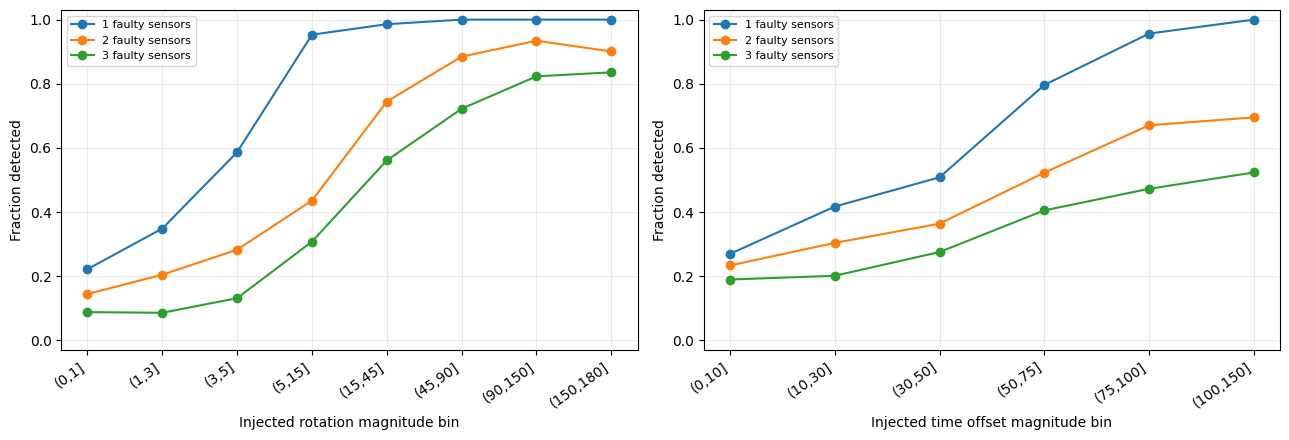

In [11]:
rotation_bins = (-0.01, 0.01, 1., 3., 5., 15., 45., 90., 150., 180.)
rotation_labels = ('zero', '(0,1]', '(1,3]', '(3,5]', '(5,15]', '(15,45]', '(45,90]', '(90,150]', '(150,180]')
time_bins = (-0.01, 0.01, 10., 30., 50., 75., 100., 150.001)
time_labels = ('zero', '(0,10]', '(10,30]', '(30,50]', '(50,75]', '(75,100]', '(100,150]')

fault_rows = inspect_df[inspect_df.injected_sensor == 1].copy()
fault_rows['rotation_bin'] = pd.cut(fault_rows.true_rotation_deg, bins=rotation_bins, labels=rotation_labels)
fault_rows['time_bin'] = pd.cut(fault_rows.true_tau_ms.abs(), bins=time_bins, labels=time_labels)

rotation_breakdown = fault_rows[fault_rows.true_rotation_deg > 0.01].groupby(
    ['fault_count', 'sensor', 'rotation_bin'], observed=True, as_index=False).agg(
    n=('alarm', 'size'), fraction_alarm_any=('alarm', 'mean'), fraction_alarm_rot=('alarm_rot', 'mean'),
    fraction_alarm_time=('alarm_time', 'mean'), mean_pred_rotation_deg=('predicted_rotation_deg', 'mean'))
time_breakdown = fault_rows[fault_rows.true_tau_ms.abs() > 0.01].groupby(
    ['fault_count', 'sensor', 'time_bin'], observed=True, as_index=False).agg(
    n=('alarm', 'size'), fraction_alarm_any=('alarm', 'mean'), fraction_alarm_rot=('alarm_rot', 'mean'),
    fraction_alarm_time=('alarm_time', 'mean'), mean_pred_time_ms=('predicted_abs_tau_ms', 'mean'))
rotation_breakdown.to_csv(OUTPUT_DIR / 'detection_by_actual_rotation_bin.csv', index=False)
time_breakdown.to_csv(OUTPUT_DIR / 'detection_by_actual_time_bin.csv', index=False)
print('Detection rates by true angle bin (each row is a truly injected sensor):')
display(rotation_breakdown.round(3))
print('Detection rates by true time offset bin:')
display(time_breakdown.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for k in (1, 2, 3):
    for ax, table, col, title in ((axes[0], rotation_breakdown, 'rotation_bin', 'Injected rotation'),
                                  (axes[1], time_breakdown, 'time_bin', 'Injected time offset')):
        filtered = table[table.fault_count == k].copy()
        filtered['weighted_alarm_count'] = filtered.n * filtered.fraction_alarm_any
        counts = filtered.groupby(col, observed=True, sort=True).agg(n=('n', 'sum'), alarms=('weighted_alarm_count', 'sum'))
        rates = counts.alarms / counts.n
        ax.plot(range(len(rates)), rates.to_numpy(), marker='o', label=f'{k} faulty sensors')
        ax.set_xticks(range(len(rates)), [str(x) for x in rates.index], rotation=35, ha='right')
        ax.set(xlabel=title + ' magnitude bin', ylabel='Fraction detected', ylim=(-0.03, 1.03))
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
finish_figure(fig, 'alarm_recall_by_rotation_and_time_magnitude.png')

## 12. Cluster-bootstrap uncertainty at one operating point

The same physical window generates 10 different fault cases. Their predictions are correlated. To avoid treating those as independent experiments, the bootstrap resamples whole physical windows (including all associated scenarios and heads). This produces descriptive 95% intervals for the **fixed operational** ground truth at the selected decision thresholds.

In [12]:
CLUSTER_BOOTSTRAP_REPEATS = 300
rng_bootstrap = np.random.default_rng(RANDOM_SEED + 739)
boot_source = inspect_df.copy()
boot_source['physical_id'] = boot_source.sequence.astype(str) + ':' + boot_source.physical_index.astype(str)
physical_ids = boot_source.physical_id.unique()


def bootstrap_counts_for_k(df, k):
    active = df if k == 'all' else df[df.fault_count == k]
    active = active.assign(tp=(active.alarm & active.operational_truth).astype(int),
                           fp=(active.alarm & ~active.operational_truth).astype(int),
                           fn=(~active.alarm & active.operational_truth).astype(int),
                           tn=(~active.alarm & ~active.operational_truth).astype(int))
    return active.groupby('physical_id')[['tp','fp','fn','tn']].sum().reindex(physical_ids, fill_value=0).to_numpy(dtype=int)


bootstrap_rows = []
for k in (1, 2, 3, 'all'):
    per_physical_counts = bootstrap_counts_for_k(boot_source, k)
    point = metrics_from_counts(*per_physical_counts.sum(axis=0))
    boot = {'precision': [], 'recall': [], 'f1': []}
    for _ in range(CLUSTER_BOOTSTRAP_REPEATS):
        drawn = rng_bootstrap.integers(0, len(physical_ids), size=len(physical_ids))
        result = metrics_from_counts(*per_physical_counts[drawn].sum(axis=0))
        for metric in boot:
            boot[metric].append(result[metric])
    for metric in boot:
        valid = np.asarray(boot[metric], dtype=float)
        valid = valid[np.isfinite(valid)]
        lower, upper = np.percentile(valid, (2.5, 97.5)) if len(valid) else (np.nan, np.nan)
        bootstrap_rows.append(dict(fault_count=k, metric=metric, point_estimate=point[metric], ci_lower=lower, ci_upper=upper,
                                   n_physical_windows=len(physical_ids), n_decisions=point['n'],
                                   rot_threshold_deg=INSPECT_ROT_THRESHOLD_DEG, time_threshold_ms=INSPECT_TIME_THRESHOLD_MS))
bootstrap_df = pd.DataFrame(bootstrap_rows)
bootstrap_df.to_csv(OUTPUT_DIR / 'selected_threshold_cluster_bootstrap.csv', index=False)
print('Approximate 95% physical-window bootstrap intervals (validation sequences are not themselves resampled):')
display(bootstrap_df.round(3))

Approximate 95% physical-window bootstrap intervals (validation sequences are not themselves resampled):


,fault_count,metric,point_estimate,ci_lower,ci_upper,n_physical_windows,n_decisions,rot_threshold_deg,time_threshold_ms
0,1,precision,0.817,0.779,0.851,344,3096,3.0,50.0
1,1,recall,0.874,0.850,0.896,344,3096,3.0,50.0
2,1,f1,0.844,0.820,0.867,344,3096,3.0,50.0
3,2,precision,0.916,0.894,0.938,344,3096,3.0,50.0
4,2,recall,0.625,0.607,0.643,344,3096,3.0,50.0
5,2,f1,0.743,0.727,0.758,344,3096,3.0,50.0
6,3,precision,0.939,0.925,0.951,344,3096,3.0,50.0
7,3,recall,0.479,0.465,0.492,344,3096,3.0,50.0
8,3,f1,0.634,0.621,0.647,344,3096,3.0,50.0
9,all,precision,0.876,0.855,0.893,344,10320,3.0,50.0


## Interpretation notes

- **Good fault detection does not imply successful recalibration.** This evaluates only whether the magnitude of the predicted correction acts as a usable alarm score.
- **Time-offset faults of 100–150 ms** and **near-179° rotational faults** are intentional stress tests. If they fall outside `002.27`'s training augmentation distribution, poor performance there is an out-of-distribution generalization result, not proof that fault detection is fundamentally impossible.
- The model is tested on **calibration mismatch**, not a broad claim of sensor reliability. Correctly calibrated LiDAR odometry can still be unreliable in fog, snow or degenerate geometry.
- **Decision thresholds and ground-truth thresholds are different concepts.** Optimize decision thresholds using the `injected` or fixed `operational` target, then check generalization on the untouched `test` sequences. The `matched` target is informative but changes its definition with every grid point.
- Since several cases share the same physical window, statistical uncertainty should ultimately be estimated by **bootstrapping physical windows or sequences**, not individual sensor rows. Counts here are descriptive, not independent-trial confidence intervals.
- If you later want to vary decision thresholds only, change `RUN_MODEL_INFERENCE = False`: all CSV metrics and plots will be regenerated from `one_step_sensor_scores.csv` without reloading/recomputing neural predictions (the model initialization can also be skipped if you refactor this notebook for analysis-only runs).